<a href="https://colab.research.google.com/github/nisaerdemli/imageprocessing/blob/main/hafta9%C3%B6dev1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Veri seti klasörü bulunamadı; test için 'test_kirmizi_cember.png' oluşturuldu.
İşlenecek görsel sayısı: 1
test_kirmizi_cember.png -> Tespit edilen kırmızı çember: 14
Kirmizi Maske (test_kirmizi_cember.png)


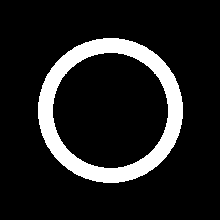

Tespit Sonucu (test_kirmizi_cember.png)


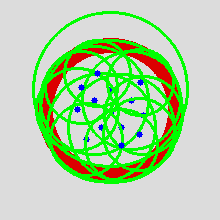

In [3]:
import glob
import os
import cv2
import numpy as np

try:
    from google.colab.patches import cv2_imshow
    COLAB_MI = True
except ImportError:
    COLAB_MI = False


def goster(baslik, goruntu):
    if goruntu is None:
        return
    if COLAB_MI:
        print(baslik)
        cv2_imshow(goruntu)
    else:
        cv2.imshow(baslik, goruntu)


def kirmizi_cember_tespit_et(bgr):
    if bgr is None or bgr.size == 0:
        return None, 0, None

    # 1. HSV renk uzayında kırmızı maske (0-12 ve 168-179 ton aralığı)
    hsv = cv2.cvtColor(bgr, cv2.COLOR_BGR2HSV)
    h, s, v = cv2.split(hsv)
    hsv_mask = (((h <= 12) | (h >= 168)) & (s >= 70) & (v >= 50)).astype(np.uint8) * 255

    # 2. YCbCr renk uzayında kırmızı krominans (Cr yüksek, Cb dengeli) maske
    ycbcr = cv2.cvtColor(bgr, cv2.COLOR_BGR2YCrCb)
    _, cr, cb = cv2.split(ycbcr)
    ycbcr_mask = ((cr >= 145) & (cb <= 140)).astype(np.uint8) * 255

    # İki renk uzayının birleşimi + morfolojik temizlik
    maske = cv2.bitwise_or(hsv_mask, ycbcr_mask)
    cekirdek = np.ones((3, 3), np.uint8)
    maske = cv2.morphologyEx(maske, cv2.MORPH_OPEN, cekirdek, iterations=1)
    maske = cv2.morphologyEx(maske, cv2.MORPH_CLOSE, cekirdek, iterations=2)

    # Kenar/maske üzerinden HoughCircles ile çember tespiti
    bulanik = cv2.medianBlur(maske, 5)
    min_r = max(6, min(bgr.shape[:2]) // 12)
    max_r = max(min_r + 5, min(bgr.shape[:2]) // 2)

    cemberler = cv2.HoughCircles(
        bulanik,
        cv2.HOUGH_GRADIENT,
        dp=1.2,
        minDist=max(10, min_r),
        param1=100,
        param2=15,
        minRadius=min_r,
        maxRadius=max_r,
    )

    sonuc = bgr.copy()
    sayac = 0

    if cemberler is not None:
        for cx, cy, r in np.round(cemberler[0, :]).astype(int):
            cember_cizgisi = np.zeros(maske.shape, dtype=np.uint8)
            cv2.circle(cember_cizgisi, (cx, cy), r, 255, thickness=3)
            kirmizi_piksel = cv2.bitwise_and(maske, cember_cizgisi)
            toplam_cizgi = max(1, np.count_nonzero(cember_cizgisi))
            oran = np.count_nonzero(kirmizi_piksel) / toplam_cizgi

            if oran >= 0.25:
                sayac += 1
                cv2.circle(sonuc, (cx, cy), r, (0, 255, 0), 2)       # Yeşil çember
                cv2.circle(sonuc, (cx, cy), 3, (255, 0, 0), -1)       # Mavi merkez

    return sonuc, sayac, maske


# Kaggle veri seti klasör yolunu kontrol et
aday_yollar = [
    "traffic-signs-dataset-germany-uk-usa",
    "traffic_signs_dataset",
    ".",
]

dosyalar = []
for yol in aday_yollar:
    if os.path.exists(yol):
        for ext in ("*.png", "*.jpg", "*.jpeg", "*.bmp"):
            bulunan = glob.glob(os.path.join(yol, "**", ext), recursive=True)
            # Kendi ürettiğimiz çıktı dosyalarını hariç tutalım
            bulunan = [f for f in bulunan if not os.path.basename(f).startswith(("cikti_", "ten_", "oylama_"))]
            if bulunan:
                dosyalar = bulunan
                break
    if dosyalar:
        break

# Eğer klasörde görsel bulunamazsa test amaçlı kırmızı çemberli örnek görsel oluştur
if not dosyalar:
    ornek = np.full((220, 220, 3), (220, 220, 220), dtype=np.uint8)
    cv2.circle(ornek, (110, 110), 65, (0, 0, 220), thickness=14)  # Kırmızı çember (BGR)
    cv2.imwrite("test_kirmizi_cember.png", ornek)
    dosyalar = ["test_kirmizi_cember.png"]
    print("Veri seti klasörü bulunamadı; test için 'test_kirmizi_cember.png' oluşturuldu.")

print(f"İşlenecek görsel sayısı: {len(dosyalar)}")

gosterilen = 0
for yol in dosyalar[:20]:
    goruntu = cv2.imread(yol, cv2.IMREAD_COLOR)
    if goruntu is None:
        print(f"Uyarı: {yol} okunamadı, atlandı.")
        continue

    cikti, adet, maske = kirmizi_cember_tespit_et(goruntu)
    print(f"{os.path.basename(yol)} -> Tespit edilen kırmızı çember: {adet}")

    if adet > 0 and gosterilen < 3:
        goster(f"Kirmizi Maske ({os.path.basename(yol)})", maske)
        goster(f"Tespit Sonucu ({os.path.basename(yol)})", cikti)
        gosterilen += 1

if not COLAB_MI:
    cv2.waitKey(0)
    cv2.destroyAllWindows()